In [4]:
from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

Some global variables

In [5]:
filter_start = "2025-10-01"
filter_end = "2026-10-01"

period_start = "2023-10-01"
period_end = "2026-10-01"

Extracting stocks

In [6]:
# EXTRACTING TICKERS. MAKE SURE TO CHANGE FILE NAME FOR ACTUAL SUBMISSION
ticker_file = "Tickers.csv"
raw_tickers = pd.read_csv(ticker_file, header=None, names=["Ticker"]) 
tickers = raw_tickers["Ticker"].drop_duplicates().tolist()  
# deletes the repeated tickers

# my updates here：
# using .get() to avoid keyerror when a field is missing
# move the volume and close to a seperate cells
# add sector info for the 40% sector weight restriction

stock_rows = []

for tick in tickers:
    t = yf.Ticker(tick)
    information = t.get_info()

    # Check if there is data in here (i.e. not a delisted or invalid ticker)
    if t.history(period='max').empty:
        print(tick, "doesn't exist")
        continue
    
    # Check if it's a CAD or USD stock traded in CA or US market
    if information.get("market") not in ["ca_market", "us_market"]:
        print(tick, "wrong market")
        continue

    # Check if it's a stock and not something like a bond or index fund
    if information.get("quoteType") != "EQUITY":
        print(tick, "not stock")
        continue

    # check currency
    if information.get("currency") not in ["CAD", "USD"]:
        print(tick, "currency wrong")
        continue

    # check sector info
    if not information.get("sector"):
        print(tick, "sector missing")
        continue

    # save stock info for later processing
    stock_rows.append({
            "Ticker": tick,
            "Currency": information.get("currency"),
            "Sector": information.get("sector")
        })

stock_info = pd.DataFrame(stock_rows).set_index("Ticker") 
# set ticker as index
listed_tickers = stock_info.index.tolist()
# save the list for filter
display(stock_info.head())

$AGN: possibly delisted; no timezone found


AGN doesn't exist


$BK: possibly delisted; no price data found  (1d 1927-12-16 -> 2026-11-21)


BK doesn't exist


$CELG: possibly delisted; no timezone found


CELG doesn't exist


$MON: possibly delisted; no timezone found


MON doesn't exist


$RTN: possibly delisted; no timezone found


RTN doesn't exist


,Currency,Sector
Ticker,,
AAPL,USD,Technology
ABBV,USD,Healthcare
ABT,USD,Healthcare
ACN,USD,Technology
AIG,USD,Financial Services


In [7]:
# Filters out the first and last trading day of each month
# idx = close_prices.index.to_series()
# date_series_first=idx.groupby([idx.dt.year, idx.dt.month]).first()
# date_series_last=idx.groupby([idx.dt.year, idx.dt.month]).last()
# monthly_first = []
# monthly_last = []
# for i in date_series_first:
#     monthly_first.append(i)
# for i in date_series_last:
#     monthly_last.append(i)

# for i in range(len(monthly_first)):
#     start_ind = close_prices.index.get_loc(monthly_first[i])
#     end_ind = close_prices.index.get_loc(monthly_last[i])

#     if (end_ind - start_ind + 1) < 18:
#         close_prices.drop(close_prices.loc[monthly_first[i]:monthly_last[i]].index)

# I suggest move volume check and valid trading dasy for each stock separately


# i.e. we can delete this cell


In [8]:
# download historical exchange rate data
history = yf.download(
    listed_tickers + ["CAD=X"],
    start=period_start,
    end=period_end,
    threads=False,
)

# download close, volume and foreign exchange info
close_prices = history["Close"][listed_tickers]
# get closing price info
volume_data = history["Volume"][listed_tickers]
# get volume info
cad_per_usd = history["Close"]["CAD=X"]
# get USD to CAD exchange info

[*********************100%***********************]  36 of 36 completed


In [9]:
# create a seperate volume data for filter
volume_data = volume_data.loc[(volume_data.index >= filter_start) & (volume_data.index < filter_end)]
print(f"volume screening period: {volume_data.index.min()}, {volume_data.index.max()}")

# updates:
# average daily trading volume = total volume traded over a period (volume) / # of trading dasy in the period
# since months with fewer than 18 valid trading days may affect the average daily trading volume
# 1. filter out months with fewer than 18 valid trading days before calculating liquidity
# 2. use only eligible months to calculate liquidity and determine eligible_tickers

eligible_tickers = []
average_volume = {} 

for ticker in listed_tickers:
    volume = volume_data[ticker].dropna()  
    # delete missed value
    volume_days = []

    for month, monthly_volume in volume.groupby(volume.index.to_period("M")): 
        if len(monthly_volume) >= 18:  
            volume_days.extend(monthly_volume)  

    average_volume[ticker] = pd.Series(volume_days).mean()  
    # transfer list to series to calculate average trading volume
    if average_volume[ticker] >= 5_000:
        eligible_tickers.append(ticker)

stock_info["Average Daily Volume"] = pd.Series(average_volume)  
print(f"{len(eligible_tickers)} eligible stocks.")

display(stock_info["Average Daily Volume"].head())

volume screening period: 2025-10-01 00:00:00, 2026-09-30 00:00:00
35 eligible stocks.


Ticker
AAPL    4.828203e+07
ABBV    6.281745e+06
ABT     1.008423e+07
ACN     6.116120e+06
AIG     4.324195e+06
Name: Average Daily Volume, dtype: float64

In [10]:
# updates:
# make sure all stocks are using the same currency

# convert prices to CAD
cad_prices = close_prices[eligible_tickers].copy()
for ticker in eligible_tickers:
    if stock_info.loc[ticker, "Currency"] == "USD":
        # if currency is USD, then change to CAD
        cad_prices[ticker] = cad_prices[ticker] * cad_per_usd
        # match closing price and exchange rate by date

cad_prices = cad_prices.dropna()  
# delete dates which missing info

In [11]:
# After all filtering, this is the table that contains all the complete data for the full consideration period, and valid stocks
# No CBIL.TO in this

display(cad_prices.head())

Ticker,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,PYPL,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319200,121.325726,393.013010,76.241152,175.725132,195.350744,254.954813,33.728010,6.02,...,78.610931,141.522601,73.839996,17.100689,70.040115,198.282212,655.916171,257.465480,174.719987,38.394420
2023-10-03,232.456407,180.677267,122.319401,393.376016,75.013726,170.570816,190.994155,258.372658,32.977460,5.98,...,77.500914,141.424391,70.440002,17.204721,69.378120,196.408601,654.323978,260.870999,174.530893,37.721729
2023-10-04,234.716907,181.429975,122.433547,398.388477,76.116896,174.105576,193.537728,255.990027,33.094829,5.86,...,79.408646,141.326139,72.230003,17.756870,69.195206,197.781115,657.373793,259.558983,174.915318,37.691547
2023-10-05,237.011686,181.598940,123.452841,399.756958,77.327381,173.121948,195.441646,256.040701,33.333050,5.20,...,78.130362,141.623504,71.510002,18.100964,69.997543,194.697581,666.297808,258.126512,174.975263,38.550101
2023-10-06,239.833993,182.060462,123.977218,401.894164,78.033789,175.378129,197.848911,256.817403,33.252432,5.15,...,78.304578,142.615879,73.269997,18.044947,70.359047,196.517888,675.474363,259.738355,175.497638,38.430051


## LOW VOLATILITY PORTFOLIO:

Step 1. Create dataframe to store daily CAD close price of S&P 500 market index.
- explain why chose S&P 500 (represents US stocks, also largely Canadians too, most diversified, its equal weight)
- converted to CAD to allow CAD calculations of beta

In [12]:
market_history = yf.download("^GSPC", start=period_start, end=period_end, threads=False)["Close"]

market_cad = (market_history["^GSPC"] * cad_per_usd).to_frame("Market")

# drop days where mismatch in market exchange and S&P500 availability
market_cad = market_cad.dropna()

# Merge SP500 and valid tickers dataframes, dropping any dates with mismatch in markets
aligned_prices = pd.concat([cad_prices[eligible_tickers], market_cad], axis=1, join="inner").dropna()
# Calculate returns, dropping days (list first day) with no valid calculation
aligned_returns = aligned_prices.pct_change().iloc[1:].dropna()

# Aligned_prices is used for closing price data for all subsequent calculations
display(aligned_prices.head())
# Aligned_returns is used for daily return data for all subsequent calculations
display(aligned_returns.head())

[*********************100%***********************]  1 of 1 completed


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319200,121.325726,393.013010,76.241152,175.725132,195.350744,254.954813,33.728010,6.02,...,141.522601,73.839996,17.100689,70.040115,198.282212,655.916171,257.465480,174.719987,38.394420,5820.932201
2023-10-03,232.456407,180.677267,122.319401,393.376016,75.013726,170.570816,190.994155,258.372658,32.977460,5.98,...,141.424391,70.440002,17.204721,69.378120,196.408601,654.323978,260.870999,174.530893,37.721729,5784.322991
2023-10-04,234.716907,181.429975,122.433547,398.388477,76.116896,174.105576,193.537728,255.990027,33.094829,5.86,...,141.326139,72.230003,17.756870,69.195206,197.781115,657.373793,259.558983,174.915318,37.691547,5845.217719
2023-10-05,237.011686,181.598940,123.452841,399.756958,77.327381,173.121948,195.441646,256.040701,33.333050,5.20,...,141.623504,71.510002,18.100964,69.997543,194.697581,666.297808,258.126512,174.975263,38.550101,5852.541619
2023-10-06,239.833993,182.060462,123.977218,401.894164,78.033789,175.378129,197.848911,256.817403,33.252432,5.15,...,142.615879,73.269997,18.044947,70.359047,196.517888,675.474363,259.738355,175.497638,38.430051,5905.100605


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099,-0.029332,-0.022301,0.013406,-0.022253,-0.006645,...,-0.000694,-0.046045,0.006084,-0.009452,-0.009449,-0.002427,0.013227,-0.001082,-0.017521,-0.006289
2023-10-04,0.009724,0.004166,0.000933,0.012742,0.014706,0.020723,0.013318,-0.009222,0.003559,-0.020067,...,-0.000695,0.025412,0.032093,-0.002636,0.006988,0.004661,-0.005029,0.002203,-0.000800,0.010528
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903,-0.005650,0.009837,0.000198,0.007198,-0.112628,...,0.002104,-0.009968,0.019378,0.011595,-0.015591,0.013575,-0.005519,0.000343,0.022778,0.001253
2023-10-06,0.011908,0.002541,0.004248,0.005346,0.009135,0.013032,0.012317,0.003034,-0.002419,-0.009615,...,0.007007,0.024612,-0.003095,0.005165,0.009349,0.013772,0.006244,0.002985,-0.003114,0.008981
2023-10-10,-0.004111,-0.004790,-0.002180,-0.008722,-0.004251,0.002635,0.001549,0.023386,0.026593,-0.048544,...,0.003644,0.020882,0.005322,0.009022,-0.004969,-0.010211,0.009903,-0.000914,0.013569,0.002304


Step 2.
- comput stats to be used for each stock

In [13]:
# updates
# approach to calculate mean, std, and beta, which gives equal weight to all data
# it is used for the low-risk portfolio selection only so far

# Get rid of market from new returns dataframe
daily_returns = aligned_returns[eligible_tickers]

# calculate the mean daily returns of each stock
mean_returns = daily_returns.mean()  

# calculate the standard deviation of daily returns of stocks
daily_std = daily_returns.std(ddof=1)  

# calculate beta for each stock:
market_var = aligned_returns["Market"].var()

# Calc and store beta for each valid stock
betas = {}
for tick in eligible_tickers:
    temp = aligned_returns[[tick, "Market"]]
    betas[tick] = (temp.cov() / market_var).iat[0, 1] 

# turn dict into a series (column to be added)
betas = pd.Series(betas)

stock_stats = stock_info.loc[eligible_tickers].copy()
stock_stats["Mean Return"] = mean_returns
stock_stats["Std"] = daily_std
stock_stats["Beta"] = betas

# These are the dataframes with the statistics we need
display(daily_returns.iloc[:5, :5])
display(stock_stats.head())


# Calculate risk score for each stock (equal weight average of std and beta)


,AAPL,ABBV,ABT,ACN,AIG
Date,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099
2023-10-04,0.009724,0.004166,0.000933,0.012742,0.014706
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903
2023-10-06,0.011908,0.002541,0.004248,0.005346,0.009135
2023-10-10,-0.004111,-0.004790,-0.002180,-0.008722,-0.004251


,Currency,Sector,Average Daily Volume,Mean Return,Std,Beta
Ticker,,,,,,
AAPL,USD,Technology,4.828203e+07,0.001117,0.017513,1.080500
ABBV,USD,Healthcare,6.281745e+06,0.001108,0.016273,0.356590
ABT,USD,Healthcare,1.008423e+07,0.000300,0.014879,0.254821
ACN,USD,Technology,6.116120e+06,-0.000335,0.021639,0.688471
AIG,USD,Financial Services,4.324195e+06,0.000552,0.014738,0.553413


Step 3. Rank all stocks using their daily std and beta.
Our reasoning:
- continuity in ranking doesn't lose info or make stocks with different risk assessment equal according to algo
- std measures how risky it is, beta measures how much it moves with overall market
- can't reduce market risk with diversification but can minimize it by reducing beta of stocks chosen
- use to construct portfolio using safest stocks first

- explain that we use beta parameters similar to the trading period (daily, etc.)

- we do not use arbitrary scores and add them to combine, instead we standardize them to a z score (assumed normal distribution), then give equal weight to each
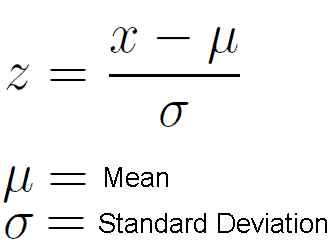

In [14]:
# calculate std z score and beta z score and add to the table above

std_weight = 0.5 # Can back test to see what's the ideal weighting if we have time
beta_weight = 0.5

std_z = (stock_stats["Std"] - stock_stats["Std"].mean()) / stock_stats["Std"].std()
beta_z = (stock_stats["Beta"] - stock_stats["Beta"].mean()) / stock_stats["Beta"].std()

# Combine z scores into a risk score in the dataframe
stock_stats["Risk Score"] = std_weight * std_z + beta_weight * beta_z

# Sort the dataframe, lower risk score is safer
stock_stats = stock_stats.sort_values("Risk Score")

# convert risk score sorted stocks into a list
ranked = stock_stats.index.tolist()

display(stock_stats.head())

,Currency,Sector,Average Daily Volume,Mean Return,Std,Beta,Risk Score
Ticker,,,,,,,
KO,USD,Consumer Defensive,1.665754e+07,0.000836,0.010964,0.104582,-1.226047
T.TO,CAD,Communication Services,7.888837e+06,-0.000411,0.012284,0.003824,-1.218950
CL,USD,Consumer Defensive,5.909059e+06,0.000493,0.012792,0.113327,-1.070920
MO,USD,Consumer Defensive,9.059322e+06,0.001119,0.014098,0.032147,-1.045778
PEP,USD,Consumer Defensive,7.808363e+06,-0.000097,0.013260,0.162332,-0.985400


Step 4. Greedy picker:
greedy picker algorithm picks the next stock in the table that:
- reduces std by the most amount (given equal weight between current portfolio and the new stock)
- track a tally of number of stocks in each industry
- track a tally of all stocks in the portfolio
- If the stocks in total is still not enough, allow the reduction of std to be positive, i.e. gain in std but by littlest amount to meet portfolio requirements
- Stop when minimum number of stocks is met and also adding more increases std, so not necessarily all 20 stocks but will be near it, and will avoid taking high volatlity stocks with the highest risk scores


In [15]:
# create combined_std, a function which calculates the std of an equal weighted portfolio given the list of its tickers, tickers
def combined_std(tickers):

    # every stock gets equal weight
    weights = 1 / len(tickers)

    returns = 0
    
    for tick in tickers:
        returns = returns + weights * daily_returns[tick]
        
    # return standard deviation of daily portfolio returns
    return returns.std(ddof=1)

In [24]:
# max any one sector can contribute to a portfolio
sector_limit = 0.4

# dict to store running tally of number of stocks from each sector
sector_tally = {}

min_stocks = 10
max_stocks = 20
# max number of stocks per sector = 40% of minimum 10 stocks = 4 stocks per sector, also adds industry diversification to reduce business risk
max_per_sector = int(sector_limit * min_stocks)
# IM NOT SURE EXACTLY HOW THIS CAN BE MADE DYNAMIC? WE DONT HAVE THE TOTAL NUMBER OF STOCKS OR EVEN THE WEIGHTINGS SO NOT MUCH WE CAN DO?

# list to store selected stocks for portfolio
selected = []

# initialize tally for each sector so far
for tick in ranked:
    sector_tally[stock_stats.loc[tick, "Sector"]] = 0

# start with the safest stock in selected
selected.append(ranked[0])

# add 1 to its sector tally
sector_tally[stock_stats.loc[ranked[0], "Sector"]] = 1

# total number of stocks in portfolio
total_count = 1

# std of current portfolio to compare to
current_std = combined_std(selected)

# allow safe stocks to be added if they increase std very slightly, since they still reduce risk to shocks, by holding less in any 1 stock
std_tolerance = 0.005 * current_std

while total_count < max_stocks:
    # starting std of portfolio in current iteration (whatever stocks are in selected + the best stock found so far down the ranked list)
    best_tick = None
    best_std = None

    # loop through safe ranked stocks top down
    for tick in ranked:
        # skip any stocks already chosen for portfolio
        if tick in selected:
            continue

        # find the current stock's sector
        sector = stock_stats.loc[tick, "Sector"]
        # temporarily add 1 to that sector's tally for a check
        temp_tally = sector_tally[sector] + 1

        # if adding another stock from that sector goes over the limit, skip that stock
        if temp_tally > max_per_sector:
            continue
            
        # calculate std if this stock were to be added to portfolio
        new_std = combined_std(selected + [tick])

        # skip the stock if the new std is worse
        if best_std is not None and new_std >= best_std:
            continue

        # if the stock passed all the tests
        best_tick = tick
        best_std = new_std

    # no stock fits requirements to be added to portfolio, so go with current portfolio
    if best_tick is None:
         break

    # how much is this new portfolio's std compared to old one's
    change = best_std - current_std

    # if adding the stock worsens std and we have already met minimum stock requirement, don't add it
    if change >= std_tolerance and total_count >= min_stocks:
        break

    # otherwise: adding the stock lowers std, or we still need more stocks to reach the minimum
    selected.append(best_tick)
    sector_tally[stock_stats.loc[best_tick, "Sector"]] += 1
    total_count += 1
    current_std = best_std

print("Selected:", selected)
print("Total stocks:", total_count)
print("Stocks per sector:", sector_tally)
print("Equal-weight portfolio daily std:", current_std)

Selected: ['KO', 'RY.TO', 'TD.TO', 'T.TO', 'LMT', 'MO', 'AMZN', 'CL', 'ABT', 'CAT', 'PEP', 'UNH']
Total stocks: 12
Stocks per sector: {'Consumer Defensive': 4, 'Communication Services': 1, 'Financial Services': 2, 'Healthcare': 2, 'Industrials': 2, 'Technology': 0, 'Consumer Cyclical': 1}
Equal-weight portfolio daily std: 0.006768685284985471


Correlation matrix

In [17]:
def weighted_corr(t1, t2):
    d1 = full_data[t1].pct_change(fill_method=None)
    d2 = full_data[t2].pct_change(fill_method=None)
    return d1.ewm(halflife=half_life).corr(d2).dropna().iloc[-1]

In [18]:
corr_mat = pd.DataFrame()

for t1 in close_prices:
    for t2 in close_prices:
        corr_mat.loc[t1, t2] = weighted_corr(t1, t2)

NameError: name 'full_data' is not defined

In [ ]:
display(corr_mat)

## HIGH RETURNS PORTFOLIO:

In [ ]:
# Add complete CBIL.TO data to cad_prices to create full_data

full_data = cad_prices.copy()

full_data["CBIL.TO"] = yf.download("CBIL.TO", period_start, period_end, auto_adjust=True)["Close"]

display(full_data.head())

Sharpe calculation

In [ ]:
half_life = 100

In [ ]:
def get_stats(tick, half_life):
    s = full_data[tick].dropna()
    delta = np.log(1 + s.pct_change()).ewm(halflife = half_life)
    standard_deviation = delta.std().iloc[-1]
    average = delta.mean().iloc[-1]

    return average, standard_deviation

In [ ]:
Rf = get_stats("CBIL.TO", half_life)[0]
print("Risk free return:", Rf)

sharpe = {}

for tick in close_prices:
    stats = get_stats(tick, half_life)
    sharpe[tick] = (stats[0] - Rf)/stats[1]

sharpe = dict(sorted(sharpe.items(), key = lambda item:item[1]))
print(sharpe)